##1. Importação das Bibliotecas


In [ ]:
import numpy as np #Utilizado para cálculos numéricos
import matplotlib.pyplot as plt #Utilizado para gerar gráficos
import pandas as pd #Utilizado para trabalhar com tabela de dados
from sklearn.preprocessing import LabelEncoder #Utilizado para transformar texto em números
from sklearn.model_selection import train_test_split #Utilizado para separar os grupos de treino e teste no Dataset
from sklearn.tree import DecisionTreeClassifier #Utilizada para fazer a Árvore de Decisões
from sklearn.metrics import accuracy_score #Utilizado para fazer o teste de acurácia
from sklearn.metrics import classification_report #Utilizado para fazer o relatório de classificação
from sklearn.metrics import confusion_matrix #Utilizado para exibir a Matrix de Confusão
from sklearn.metrics import ConfusionMatrixDisplay #Utilizado para exibir o gráfico da Matrix de Confusão
from sklearn import tree #Utilizado para montar o gráfica da árvore de decisões

##2. Carregamento e Inspeção Inicial dos Dados

In [ ]:
#Montando o Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
#Importando o dataset
dataset = pd.read_csv('/content/drive/MyDrive/Lab_IA/Dataset/Crop_recommendation.csv', sep=',')

In [ ]:
#Renomeando as colunas do Dataset
col_names = ['Nitrogenio', 'Fosforo', 'Potassio', 'Temperatura', 'Umidade', 'pH', 'Precipitação', 'Label']

dataset.columns = col_names

col_names

['Nitrogenio',
 'Fosforo',
 'Potassio',
 'Temperatura',
 'Umidade',
 'pH',
 'Precipitação',
 'Label']

In [ ]:
#Verificando informações do Dataset
dataset.head(10)

,Nitrogenio,Fosforo,Potassio,Temperatura,Umidade,pH,Precipitação,Label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
5,69,37,42,23.058049,83.370118,7.073454,251.055000,rice
6,69,55,38,22.708838,82.639414,5.700806,271.324860,rice
7,94,53,40,20.277744,82.894086,5.718627,241.974195,rice
8,89,54,38,24.515881,83.535216,6.685346,230.446236,rice
9,68,58,38,23.223974,83.033227,6.336254,221.209196,rice


In [ ]:
#Formato Dataset
print("Formato: ", dataset.shape)

Formato:  (2200, 8)


In [ ]:
#Tipos de cada coluna
print(dataset.dtypes)

Nitrogenio        int64
Fosforo           int64
Potassio          int64
Temperatura     float64
Umidade         float64
pH              float64
Precipitação    float64
Label            object
dtype: object


In [ ]:
#Quantidade de valores nulos no dataset
dataset.isnull().sum()

,0
Nitrogenio,0
Fosforo,0
Potassio,0
Temperatura,0
Umidade,0
pH,0
Precipitação,0
Label,0


##3. Separação de Atributos Preditores ($X$) e Variável Alvo ($y$)

In [ ]:
#Variáveis de Features | Variáveis de Target
X = dataset.iloc[:, :-1].values
y = dataset.iloc[:, -1].values

In [ ]:
#Exibindo 5 Features | Nitrogenio	Fosforo	Potassio	Temperatura	Umidade	pH	Chuva |
print(X[:5])

[[ 90.          42.          43.          20.87974371  82.00274423
    6.50298529 202.9355362 ]
 [ 85.          58.          41.          21.77046169  80.31964408
    7.03809636 226.6555374 ]
 [ 60.          55.          44.          23.00445915  82.3207629
    7.84020714 263.9642476 ]
 [ 74.          35.          40.          26.49109635  80.15836264
    6.9804009  242.8640342 ]
 [ 78.          42.          42.          20.13017482  81.60487287
    7.62847289 262.7173405 ]]


In [ ]:
#Exibindo 5 Targets | Label |
print(y[:5])

['rice' 'rice' 'rice' 'rice' 'rice']


In [ ]:
#Transformando os textos da coluna Label em representações numéricas
le = LabelEncoder()
y = le.fit_transform(y)

In [ ]:
#Exibindo as representações numéricas
print(y)

[20 20 20 ...  5  5  5]


##4. Divisão em Conjuntos de Treino e Teste

In [ ]:
#Divindo o Dataset em grupos de Treino e Teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42, stratify=y)

In [ ]:
#Exibindo os dados de treino X
print(X_train)

[[  0.          18.          14.         ...  92.00719952   7.20799126
  114.4161786 ]
 [  9.         122.         201.         ...  80.91934392   5.57029054
   68.06417307]
 [ 11.          71.          24.         ...  22.7182355    5.60662035
  141.6056722 ]
 ...
 [ 82.          48.          36.         ...  81.76904006   6.35207678
  193.2418382 ]
 [ 90.          50.          44.         ...  73.48655995   6.25340885
  171.4716375 ]
 [  1.         132.         200.         ...  82.94270065   5.62074564
   66.57462809]]


In [ ]:
#Exibindo os dados de Teste X
print(X_test)

[[ 13.          23.           6.         ...  90.26408017   7.36533811
  102.6958703 ]
 [ 98.          79.          50.         ...  84.47321314   6.43591731
   91.06493353]
 [140.          38.          15.         ...  75.88298598   6.02143952
   69.91563467]
 ...
 [ 70.          38.          35.         ...  79.26861738   7.01406394
  164.2697011 ]
 [ 21.         134.         202.         ...  80.02130636   6.42541993
   65.2982112 ]
 [ 36.          67.          25.         ...  36.52780776   6.41806265
  136.0456753 ]]


In [ ]:
#Exibindo os dados de Treino Y
print(y_train)

[16  7  9 ...  8  8  7]


In [ ]:
#Exibindo os dados de Teste Y
print(y_test)

[16  1  6 11 16  3 20  2  1 16 21 19 21 11 13  7  7 12 12  0  2  0 13  9
  0  8 13 21 20  5 12  8  1  5  8  2  7  7  2  8  4 17 12 11 10  8  6 10
  3 14 17 19 18 21 12  2 17 17  5 10 10 13  5  1 17 20 16  4  2 19  1 15
 21 10  1  4 13 14 14 12  5 21 15  9 12 19 16  6  4 17 13 14 13  6  8  7
  6  3  8 21 15 19 16 18 18  7  9 10 20 20  0 14 14  7 20 15  2 10  1 16
 16  3 11 12 11 10  1 19  4 14  6  3  8 14 13 11  0  3 20 11  6  8 19 12
 20 17  1 16 18 10 11  3  6 21 13 11 18 15  0 14  2  3 11 11  9  5 16 11
  7 19  0  4 15  7  6 10 18  3  2 13  0 15  6 21 15 21 16 21  5  9  0  3
  2  5 15  5  0  7  8 17  4  7 21 14 19 18 14 10 17 15  3  0 11  3  1 19
 19 11 16  8  6  6 11  7 14 10 18 17 14  0  1 20  3 11 20 16  2  4 20  7
  9  6 14 14  4  0 10 17 19  3  9  9 18  8 15 19  2  3 15 12  3 21  3 19
 12 13  6  8  0  9  4 17  5  9  4  4  2 10  9 14  5  6  7  5  2 13 10 21
 19  0 16 12  8  1 10 14  2 13 21 18 10  1  0  1 21  2  9 20 17  1  9  1
 15 15 16 11  1 18  8  0 10 15  4 17  8  6 16 16  2

In [ ]:
#Exibindo o tamanho dos dados de treino e teste do X
X_train.shape, X_test.shape

((1760, 7), (440, 7))

In [ ]:
#Exibindo o tamanho dos de treino e teste do Y
y_train.shape, y_test.shape

((1760,), (440,))

##5. Treinamento do Modelo de Árvore de Decisão

In [ ]:
#Instanciando a árvore de decisões
clf = DecisionTreeClassifier(criterion='gini', max_depth=11, random_state=42)

In [ ]:
#Treinando o modelo
clf = clf.fit(X_train, y_train)

In [ ]:
#Representando a importância de cada atributo
clf.feature_importances_

array([0.14549376, 0.22730601, 0.09928963, 0.0034163 , 0.20156104,
       0.        , 0.32293325])

In [ ]:
#Exibindo os valores da importância de cada atributo
feature_names = col_names[:-1]
for feature, importancia in zip(feature_names, clf.feature_importances_):
    print("{}:{}".format(feature, importancia))

Nitrogenio:0.14549376334078754
Fosforo:0.22730601369987374
Potassio:0.0992896270956996
Temperatura:0.0034162985519140946
Umidade:0.20156104444329248
pH:0.0
Precipitação:0.32293325286843266


##6. Avaliação do Desempenho no Conjunto de Teste

In [ ]:
#Prevendo os valores de acordo com as features e exibindo os resultados
y_pred = clf.predict(X_test)
y_pred

array([16,  1,  6, 11, 16,  3, 20,  2,  1, 16, 21, 19, 21, 11, 13,  7,  7,
       12, 12,  0,  2,  0, 13,  9,  0,  8, 13, 21, 20,  5, 12,  8,  1,  5,
        8,  2,  7,  7,  2,  8,  4, 17, 12, 11, 10,  8,  6, 10,  3, 14, 17,
       19, 18, 21, 12, 10, 17, 17,  5, 10, 10, 13,  5,  1, 17, 20, 16,  4,
        2, 19,  1, 15, 21, 10,  1,  4, 13, 14, 14, 12,  5, 21, 15,  9, 12,
       19, 16,  6,  4, 17, 13, 14, 13,  6,  8,  7,  6,  3,  8, 21, 15, 19,
       16, 18, 18,  7,  9, 10, 20, 20,  0, 14, 14,  7, 20, 15,  2, 10,  1,
       16, 16,  3, 11, 12, 11, 10,  1, 19,  4, 14,  6,  3,  8, 14, 13, 11,
        0,  3, 20, 11,  6,  8, 19, 12,  8, 17,  1, 16, 18, 10, 11,  3,  6,
       21, 13, 11, 18, 15,  0, 14,  2,  3, 11, 11,  9,  5, 16, 11,  7, 19,
        0,  4, 15,  7,  6, 10, 18,  3, 11, 13,  0, 15,  6, 21, 15, 21, 16,
       21,  5,  9,  0,  3,  2,  5, 15,  5,  0,  7,  8, 17,  4,  7, 21, 14,
       19, 18, 14, 13, 17, 15,  3,  0, 11,  3,  1, 19, 19, 11, 16,  8,  6,
        6, 11,  7, 14, 10

In [ ]:
#Calculando a acurácia e comparando com os valores reais e os previstos
accuracy = accuracy_score(y_pred, y_test)

In [ ]:
#Exibindo a acurácia
print("Acurácia:", accuracy)

Acurácia: 0.9772727272727273


In [ ]:
# Exibindo o relatório de Classificação
print(classification_report(y_test, y_pred, zero_division=0))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        20
           1       1.00      1.00      1.00        20
           2       1.00      0.80      0.89        20
           3       1.00      1.00      1.00        20
           4       1.00      1.00      1.00        20
           5       1.00      1.00      1.00        20
           6       1.00      1.00      1.00        20
           7       1.00      1.00      1.00        20
           8       0.87      1.00      0.93        20
           9       1.00      1.00      1.00        20
          10       0.86      0.90      0.88        20
          11       0.95      1.00      0.98        20
          12       1.00      1.00      1.00        20
          13       0.86      0.95      0.90        20
          14       1.00      1.00      1.00        20
          15       1.00      1.00      1.00        20
          16       1.00      1.00      1.00        20
          17       1.00    

In [ ]:
#Exibindo a Matrix de Confusão
print(confusion_matrix(y_test, y_pred))

[[20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0 16  0  0  0  0  0  0  0  2  1  0  1  0  0  0  0  0  0  0  0]
 [ 0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0 18  0  0  2  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0  0 20  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  1  0  0 19  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0  0

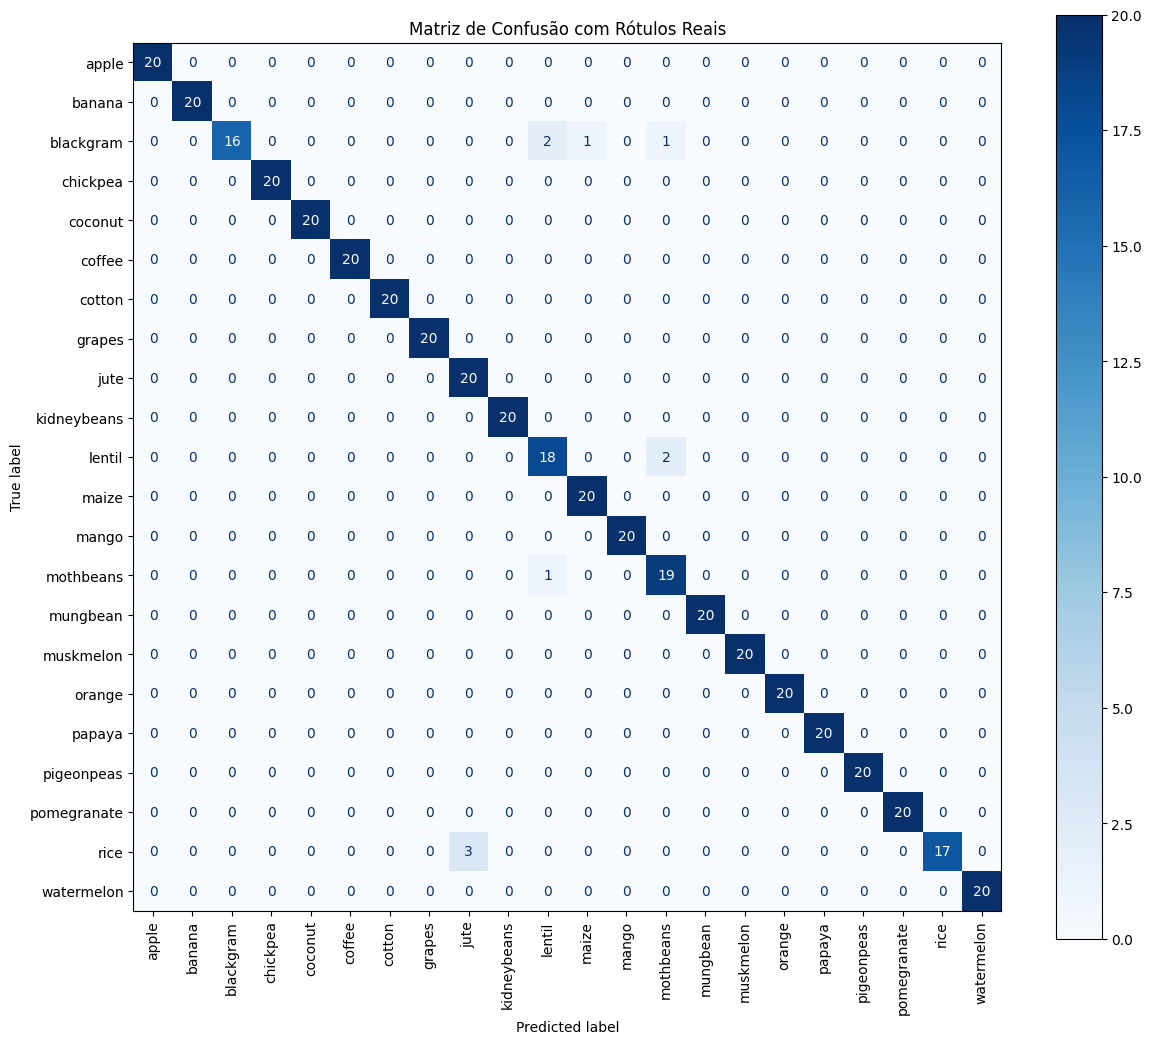

In [ ]:
#Exibindo o gráfico da Matriz de Confusão
fig, ax = plt.subplots(figsize=(14,12))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=le.classes_, xticks_rotation='vertical', ax=ax, cmap='Blues')
plt.title("Matriz de Confusão com Rótulos Reais")
plt.show()

##7. Interpretação Visual da Árvore de Decisão

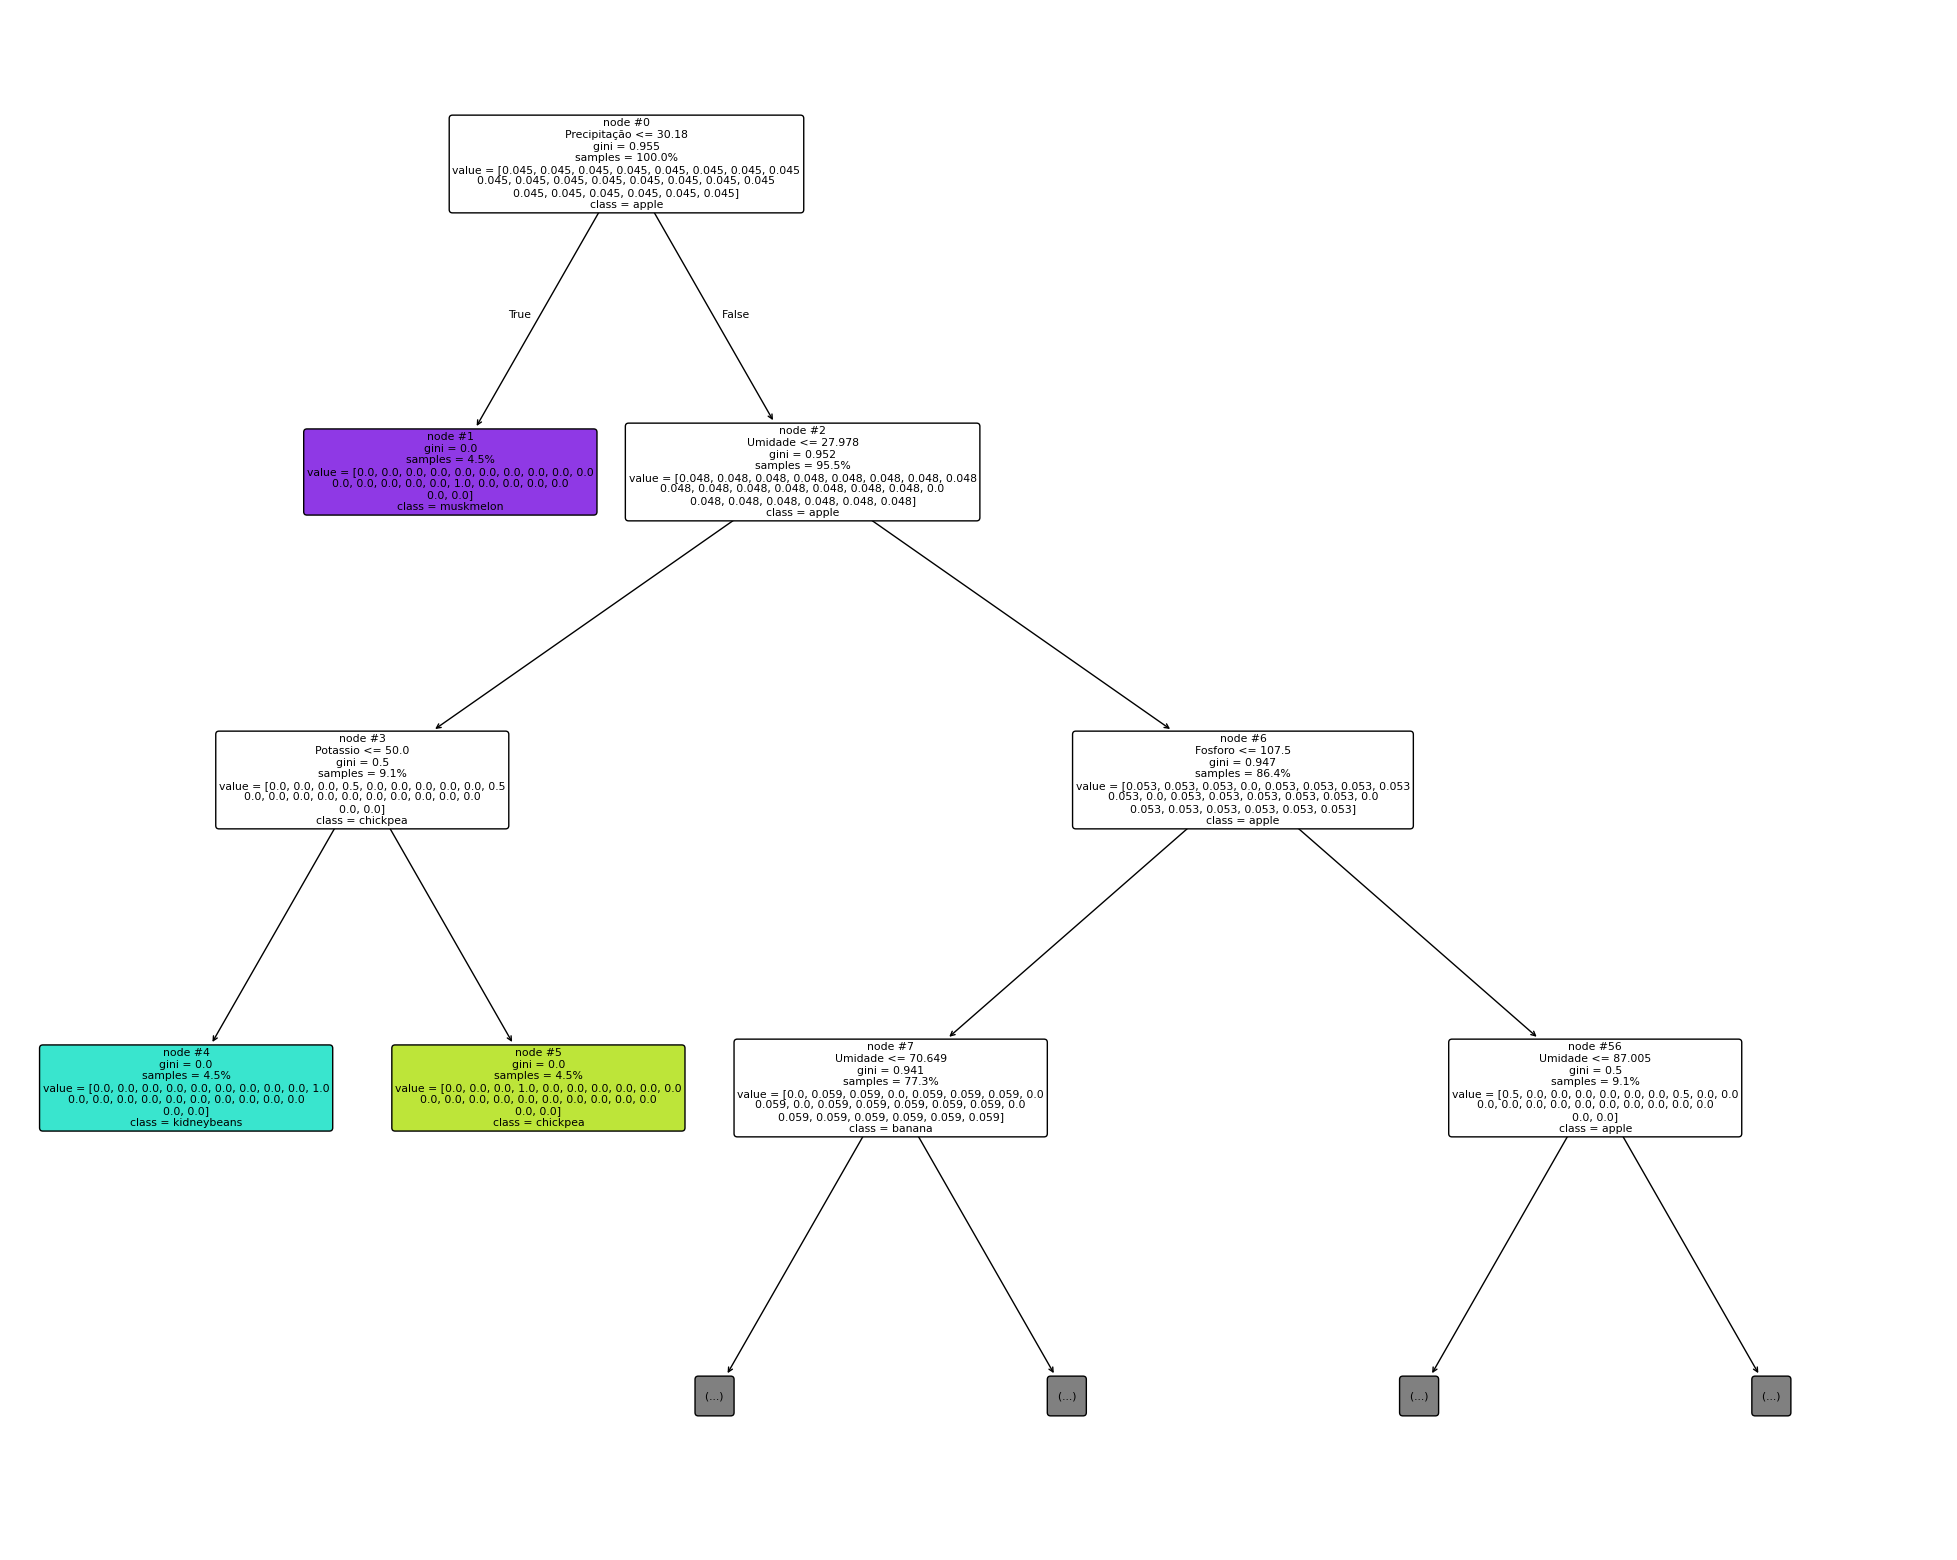

In [ ]:
#Exibindo a árvode de decisões
fig = plt.figure(figsize=(25, 20))
_ = tree.plot_tree(clf, max_depth=3, feature_names=feature_names, class_names=le.classes_, node_ids=True, filled=True, rounded=True, proportion=True, label='all')

##8. Simulação de Predição com Novos Dados

In [ ]:
#Testando o resultado com novos valores

# 1. Definindo os dados de uma nova amostra de solo/clima
# Ordem: [Nitrogenio, Fosforo, Potassio, Temperatura, Umidade, pH, Precipitação]
novo_dado = [[90, 42, 43, 20.8, 82.0, 6.5, 202.9]]

pred_classe = clf.predict(novo_dado)
cultura_recomendada = le.inverse_transform(pred_classe)

# Confiança da decisão
probabilidade = max(clf.predict_proba(novo_dado)[0]) * 100

print(f"Cultivo Recomendado: {cultura_recomendada}")
print(f"Grau de Confiança: {probabilidade:.2f}%")

Cultivo Recomendado: ['rice']
Grau de Confiança: 100.00%


##9. Comparação de Modelos: Análise de Hiperparâmetros (Profundidade da Árvore)

In [ ]:
#Criando uma árvore de decisão com a quantidade máxima de profundidade 5
clf_reduzida = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)

In [ ]:
#Treinando o modelo com a nova árvore
clf_reduzida = clf_reduzida.fit(X_train, y_train)

In [ ]:
#Predição dos novos conjunto de valores
y_pred_reduzida = clf_reduzida.predict(X_test)

In [ ]:
#Calculando a acurácia da árvore reduzida
accuracy_reduzida = accuracy_score(y_test, y_pred_reduzida)

In [ ]:
#Exibindo a acurácia da árvore com diferentes profundidades
print(f"Acurácia da Árvore Reduzida (max_depth=5): {accuracy_reduzida:.4f} ({accuracy_reduzida*100:.2f}%)")
print(f"Acurácia da Árvore Completa (max_depth=11): {accuracy:.4f} ({accuracy*100:.2f}%)")

Acurácia da Árvore Reduzida (max_depth=5): 0.4068 (40.68%)
Acurácia da Árvore Completa (max_depth=11): 0.9773 (97.73%)


In [ ]:
#Criação do Dataframe comparativo das duas árvores
df_comparacao = pd.DataFrame({
    'Modelo': ['Árvore Reduzida', 'Árvore Completa'],
    'Profundidade': [5, 11],
    'Critério': ['Gini', 'Gini'],
    'Acurácia no Teste': [f"{accuracy_reduzida*100:.2f}%", f"{accuracy*100:.2f}%"],
    'Diagnóstico': ['Underfitting (subajuste severo)', 'Ajuste ideal com alta generalização']
})

In [ ]:
#Exibição do Dataframe comparativo
df_comparacao

,Modelo,Profundidade,Critério,Acurácia no Teste,Diagnóstico
0,Árvore Reduzida,5,Gini,40.68%,Underfitting (subajuste severo)
1,Árvore Completa,11,Gini,97.73%,Ajuste ideal com alta generalização


##10. Persistência do Modelo para Deploy

In [ ]:
#Importando a bibloteca para exportação do modelo
import joblib

#Salvando os arquivos do modelo
joblib.dump(clf, 'modelo_arvore_culturas.pkl')
joblib.dump(le, 'label_encoder.pkl')



['label_encoder.pkl']